In [1]:
import os
import copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader


DATA_PATH = "kpdata1.csv"
MODEL_PATH = "best_CNN_LSTM_solar.pth"

COLUMNS = (
    ["year", "month", "day", "days", "days_m", "Bsr", "dB"]
    + [f"Kp{i}" for i in range(1, 9)]
    + [f"ap{i}" for i in range(1, 9)]
    + ["Ap", "SN", "F107obs", "F107adj", "D"]
)

WINDOW_IN = 135
WINDOW_OUT = 27

BATCH_SIZE = 32
NUM_EPOCHS = 300
LEARNING_RATE = 0.0001
PATIENCE = 25

TARGET_COLUMNS = ["SN", "F107obs"]

MIN_VALUES = np.array([0.0, 64.6], dtype=np.float32)
AMPLITUDES = np.array([428.0, 367.0], dtype=np.float32)

In [2]:
class CNNLSTM(nn.Module):

    def __init__(
        self,
        input_size=2,
        hidden_size=50,
        output_size=2
    ):
        super(CNNLSTM, self).__init__()

        self.lstm_1 = nn.LSTM(
            input_size,
            hidden_size,
            batch_first=True
        )

        self.batch_norm_output = nn.BatchNorm1d(hidden_size)
        self.batch_norm_h = nn.BatchNorm1d(hidden_size)
        self.batch_norm_c = nn.BatchNorm1d(hidden_size)

        self.lstm_2 = nn.LSTM(
            hidden_size,
            hidden_size,
            batch_first=True
        )

        self.lin = nn.Linear(
            hidden_size,
            output_size
        )

    def forward(self, x):
        lstm_output, (h, c) = self.lstm_1(x)

        output = lstm_output[:, -1, :]

        output = self.batch_norm_output(output)
        h = self.batch_norm_h(h[-1])
        c = self.batch_norm_c(c[-1])

        decoder_input = output.unsqueeze(1).repeat(
            1,
            WINDOW_OUT,
            1
        )

        decoder_output, _ = self.lstm_2(
            decoder_input,
            (
                h.unsqueeze(0),
                c.unsqueeze(0)
            )
        )

        output = self.lin(decoder_output)

        return output

In [3]:
df = pd.read_csv(
    DATA_PATH,
    sep=";",
    header=None,
    names=COLUMNS
)

df["date"] = pd.to_datetime(
    df[["year", "month", "day"]]
)

# df["F107obs"] = df["F107obs"].interpolate(
#     method="linear",
#     limit=1,
#     limit_area="inside"
# )

values = df[TARGET_COLUMNS].to_numpy(dtype=np.float32)

values_norm = (
    values - MIN_VALUES
) / AMPLITUDES

dates = pd.to_datetime(df["date"]).reset_index(drop=True)

def make_windows(data, starts):
    X = np.array([
        data[i - WINDOW_IN:i]
        for i in starts
    ], dtype=np.float32)

    y = np.array([
        data[i:i + WINDOW_OUT]
        for i in starts
    ], dtype=np.float32)

    return X, y


test_start = dates.searchsorted(
    pd.Timestamp("2020-01-01")
)

val_start = int(test_start * (1 - 0.20))


train_starts = np.arange(
    WINDOW_IN,
    val_start - WINDOW_OUT + 1
)

val_starts = np.arange(
    val_start,
    test_start - WINDOW_OUT + 1,
    WINDOW_OUT
)


X_train, y_train = make_windows(
    values_norm,
    train_starts
)

X_val, y_val = make_windows(
    values_norm,
    val_starts
)

train_loader = DataLoader(
    TensorDataset(
        torch.tensor(X_train),
        torch.tensor(y_train)
    ),
    batch_size=BATCH_SIZE,
    shuffle=True,
    drop_last=True
)

val_loader = DataLoader(
    TensorDataset(
        torch.tensor(X_val),
        torch.tensor(y_val)
    ),
    batch_size=BATCH_SIZE,
    shuffle=False
)

In [4]:
model = CNNLSTM()

if os.path.exists(MODEL_PATH):

    checkpoint = torch.load(
        MODEL_PATH,
        weights_only=True
    )

    model.load_state_dict(
        checkpoint["model_state_dict"]
    )

    history = checkpoint["history"]
else:
    loss_function = nn.L1Loss()

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=LEARNING_RATE
    )

    history = {
        "train_loss": [],
        "val_loss": []
    }

    best_val_loss = float("inf")
    best_state = copy.deepcopy(model.state_dict())
    patience_counter = 0

    for epoch in range(NUM_EPOCHS):
        model.train()

        train_loss = 0.0
        train_count = 0

        for x_batch, y_batch in train_loader:
            prediction = model(x_batch)

            loss = loss_function(
                prediction,
                y_batch
            )

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            train_loss += loss.item() * len(x_batch)
            train_count += len(x_batch)

        train_loss /= train_count

        model.eval()

        val_loss = 0.0
        val_count = 0

        with torch.no_grad():
            for x_batch, y_batch in val_loader:
                prediction = model(x_batch)

                loss = loss_function(
                    prediction,
                    y_batch
                )

                val_loss += loss.item() * len(x_batch)
                val_count += len(x_batch)

        val_loss /= val_count

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_state = copy.deepcopy(model.state_dict())

            patience_counter = 0

        else:
            patience_counter += 1

        if patience_counter >= PATIENCE:
            break

    best_epoch = np.argmin(history["val_loss"]) + 1
    model.load_state_dict(best_state)

    torch.save(
        {
            "model_state_dict": model.state_dict(),
            "history": history
        },
        MODEL_PATH
    )

model.eval()

CNNLSTM(
  (lstm_1): LSTM(2, 50, batch_first=True)
  (batch_norm_output): BatchNorm1d(50, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (batch_norm_h): BatchNorm1d(50, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (batch_norm_c): BatchNorm1d(50, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (lstm_2): LSTM(50, 50, batch_first=True)
  (lin): Linear(in_features=50, out_features=2, bias=True)
)

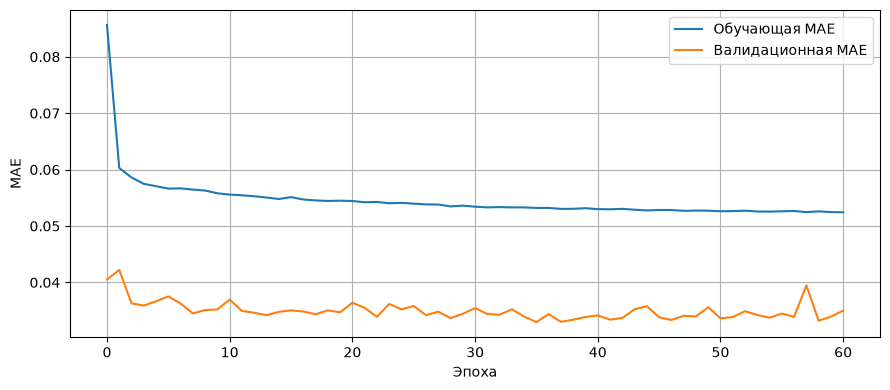

In [5]:
plt.figure(figsize=(9, 4))

plt.plot(
    history["train_loss"],
    label="Обучающая MAE"
)

plt.plot(
    history["val_loss"],
    label="Валидационная MAE"
)

plt.xlabel("Эпоха")
plt.ylabel("MAE")
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.show()

In [6]:
class MetricsCalculator:
    def calculate_comprehensive_metrics(self, y_true, y_pred, model_name=""):
        mse = mean_squared_error(y_true, y_pred)
        rmse = np.sqrt(mse)
        mae = mean_absolute_error(y_true, y_pred)
        r2 = r2_score(y_true, y_pred)
        denominator = (np.abs(y_true) + np.abs(y_pred) + 1e-10)
        mape = np.mean(2 * np.abs(y_true - y_pred) / denominator) * 100
        print(f"\n{model_name} - МЕТРИКИ КАЧЕСТВА:")
        print("-" * 40)
        print(f"MSE:  {mse:.6f}")
        print(f"RMSE: {rmse:.6f}")
        print(f"MAE:  {mae:.6f}")
        print(f"R²:   {r2:.6f}")
        print(f"MAPE: {mape:.4f}%")
        return {'MSE': mse, 'RMSE': rmse, 'MAE': mae, 'R2': r2, 'MAPE': mape}

    def approximation_quality(self, deviation, y_pred, y_true):
        y_pred = np.array(y_pred).flatten()
        y_true = np.array(y_true).flatten()
        if len(y_pred) != len(y_true):
            print(f"ОШИБКА: Разные размеры y_pred({len(y_pred)}) и y_true({len(y_true)})")
            return 0
        absolute_errors = np.abs(y_pred - y_true)
        within_deviation = np.sum(absolute_errors <= deviation)
        percentage = (within_deviation / len(y_true)) * 100
        return min(percentage, 100.0)

In [7]:
def inverse_normalize(x):
    return x * AMPLITUDES + MIN_VALUES

test_rows = []
model.eval()

def f():
    with torch.no_grad():
        for start in range(
            test_start,
            len(values_norm),
            WINDOW_OUT
        ):

            x = torch.tensor(
                values_norm[start - WINDOW_IN:start]
            ).unsqueeze(0)

            prediction = model(x).numpy()[0]

            count = min(
                WINDOW_OUT,
                len(values_norm) - start
            )

            prediction = inverse_normalize(
                prediction[:count]
            )

            actual = inverse_normalize(
                values_norm[start:start + count]
            )

            for i in range(count):
                test_rows.append({
                    "date": dates.iloc[start + i],

                    "SN_actual": actual[i, 0],
                    "SN_pred": prediction[i, 0],

                    "F107obs_actual": actual[i, 1],
                    "F107obs_pred": prediction[i, 1]
                })

f()

test_predictions = pd.DataFrame(test_rows)

In [8]:
metrics_calculator = MetricsCalculator()

metrics = metrics_calculator.calculate_comprehensive_metrics(
    y_true=test_predictions["SN_actual"],
    y_pred=test_predictions["SN_pred"],
    model_name="CNN-SN",
)

deviation_sn = 0.1 * np.std(test_predictions["SN_actual"])

quality_sn = metrics_calculator.approximation_quality(
    deviation=deviation_sn,
    y_pred=test_predictions["SN_pred"],
    y_true=test_predictions["SN_actual"]
)

print(f"Качество аппроксимации SN: {quality_sn:.2f}%")

metrics = metrics_calculator.calculate_comprehensive_metrics(
    y_true=test_predictions["F107obs_actual"],

    y_pred=test_predictions["F107obs_pred"],

    model_name="CNN-F107",
)

deviation_f107 = 0.1 * np.std(test_predictions["F107obs_actual"])

quality_f107 = metrics_calculator.approximation_quality(
    deviation=deviation_f107,
    y_pred=test_predictions["F107obs_pred"],
    y_true=test_predictions["F107obs_actual"]
)

print(f"Качество аппроксимации F10.7: {quality_f107:.2f}%")


CNN-SN - МЕТРИКИ КАЧЕСТВА:
----------------------------------------
MSE:  683.287048
RMSE: 26.139760
MAE:  17.954098
R²:   0.671182
MAPE: 79.3239%
Качество аппроксимации SN: 18.25%

CNN-F107 - МЕТРИКИ КАЧЕСТВА:
----------------------------------------
MSE:  337.018280
RMSE: 18.358058
MAE:  10.112552
R²:   0.718191
MAPE: 9.5946%
Качество аппроксимации F10.7: 46.54%
